In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [16]:
csv_path= CSV_PATH = r"C:\Users\xhani\Downloads\ai_human_content_detection_dataset.csv"
dataset=pd.read_csv(csv_path, encoding='utf-8')
dataset.head()


,text_content,content_type,word_count,character_count,sentence_count,lexical_diversity,avg_sentence_length,avg_word_length,punctuation_ratio,flesch_reading_ease,gunning_fog_index,grammar_errors,passive_voice_ratio,predictability_score,burstiness,sentiment_score,label
0,Score each cause. Quality throughout beautiful...,academic_paper,288,1927,54,0.9514,5.33,5.69,0.0280,53.08,7.41,1,0.1041,105.86,0.5531,0.2034,1
1,Board its rock. Job worker break tonight coupl...,essay,253,1719,45,0.9723,5.62,5.80,0.0262,50.32,8.10,6,0.2045,100.29,0.5643,0.4854,1
2,Way debate decision produce. Dream necessary c...,academic_paper,420,2849,75,0.9071,5.60,5.79,0.0263,46.86,7.86,5,0.2308,96.88,0.4979,-0.2369,1
3,Story turn because such during open model. Tha...,creative_writing,196,1310,34,0.9592,5.76,5.69,0.0260,53.80,7.00,2,0.1912,88.79,0.6241,NaN,1
4,Place specific as simply leader fall analysis....,news_article,160,1115,28,0.9688,5.71,5.97,0.0251,44.53,8.29,0,0.1318,26.15,0.2894,NaN,1


In [17]:
from sklearn.model_selection import train_test_split
X=dataset['text_content']
y=dataset['label']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)

In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report
tfidf=TfidfVectorizer(ngram_range=(1,2),max_features=10000)
X_train_norm=tfidf.fit_transform(X_train)
X_test_norm=tfidf.transform(X_test)

model1=MultinomialNB()
model1.fit(X_train_norm,y_train)
y_pred=model1.predict(X_test_norm)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.64      0.36      0.46       137
           1       0.55      0.80      0.65       137

    accuracy                           0.58       274
   macro avg       0.59      0.58      0.56       274
weighted avg       0.59      0.58      0.56       274



In [26]:
from sklearn.naive_bayes import GaussianNB
model2=GaussianNB()
model2.fit(X_train_norm.toarray(),y_train)
y_pred2=model2.predict(X_test_norm.toarray())
print(classification_report(y_test,y_pred2))

              precision    recall  f1-score   support

           0       0.51      0.84      0.64       137
           1       0.55      0.20      0.29       137

    accuracy                           0.52       274
   macro avg       0.53      0.52      0.46       274
weighted avg       0.53      0.52      0.46       274



In [28]:
from sklearn.naive_bayes import ComplementNB
model3=ComplementNB()
model3.fit(X_train_norm,y_train)
y_pred3=model3.predict(X_test_norm)
print(classification_report(y_test,y_pred3))

              precision    recall  f1-score   support

           0       0.63      0.35      0.45       137
           1       0.55      0.80      0.65       137

    accuracy                           0.57       274
   macro avg       0.59      0.57      0.55       274
weighted avg       0.59      0.57      0.55       274



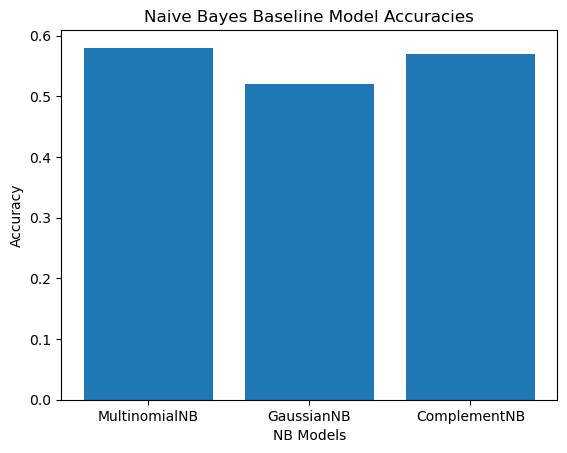

In [29]:
models=['MultinomialNB','GaussianNB','ComplementNB']
accuracies=[0.58,0.52,0.57]
plt.bar(models,accuracies)
plt.title('Naive Bayes Baseline Model Accuracies')
plt.xlabel('NB Models')
plt.ylabel('Accuracy')
plt.show()